# Tutorial: AOI + clipping helpers (Task A1)

This notebook is a from-scratch walkthrough of the two reusable pieces in `src/`: building an AOI
(`src/aoi.py`) and clipping a raw dataset to it (`src/clip.py`). It's meant as a reference for anyone
on the team who wants to reuse these helpers for their own metric (A2, A3, ...), not as a pipeline
step itself - the actual pipeline entry points are `scripts/build_aoi.py` and
`scripts/landcover_in_flood_zone.py`.

For the full task spec, see `data/_notes/HW2_task_A1.md`.

## 0. Prerequisites: get the raw data

`data/` is gitignored, so every teammate needs to download the raw files themselves. This notebook
uses two of them:

| Dataset | Source page | Save as |
|---|---|---|
| River kilometrage (points every 100 m) | https://data.public.lu/en/datasets/6a7e68b30721310f8b8410a7/ | `data/raw/River_kilometers/kilometrage-des-cours-deau.gpkg` |
| HQ100 flood hazard map (100-year flood extent) | https://data.public.lu/fr/datasets/flood-hazard-maps-100-year-flood/#/information | `data/raw/Flood_hazard_HQ100/HWGK2021_HQ100/HWGK2021_HQ100.shp` (+ its `.dbf`/`.shx`/... siblings, unzipped) |

Checksums for both files are listed in `data/_notes/HW2_task_A1.md` - verify against those before
trusting a download. **Do not re-download if the files are already present.**

## 1. Make `src/` importable

This notebook lives in `notebooks/`, one level below the repo root, and Jupyter's working directory
doesn't reliably match where the notebook file sits (depends on how you launched Jupyter/PyCharm). So
instead of assuming a fixed relative path, we search upward for `config.yaml` (a file that only exists
at the repo root) to find the repo root robustly, then add it to `sys.path` so `import src...` works.

In [1]:
import sys
from pathlib import Path


def find_repo_root(marker: str = "config.yaml") -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not find {marker} above {Path.cwd()}")


sys.path.insert(0, str(find_repo_root()))

## 2. Build (or load) the AOI

`build_aoi()` in `src/aoi.py` is a pure function: given a river name, km range, and margin, it filters
the river-kilometrage points and returns the AOI rectangle - nothing is read from or written to
`config.yaml`/`aoi.gpkg` inside the function itself. That's what makes it directly reusable from a
future dashboard slider, not just from `config.yaml`.

In [2]:
from src.aoi import build_aoi
from src.config import REPO_ROOT, load_config

config = load_config()
config

{'river': 'Alzette',
 'km_start': 46.3,
 'km_end': 48.3,
 'aoi_method': 'bbox',
 'bbox_margin_m': 300,
 'crs': 'EPSG:2169',
 'landcover_year': 2024}

In [5]:
aoi, points = build_aoi(
    river=config["river"],
    km_start=config["km_start"],
    km_end=config["km_end"],
    margin_m=config["bbox_margin_m"],
    crs=config["crs"],
    method=config["aoi_method"],
)
print(f"{len(points)} river points, AOI area = {aoi.geometry.area.sum():,.0f} m2")
aoi

21 river points, AOI area = 2,134,745 m2


,river,km_start,km_end,margin_m,method,n_points,geometry
0,Alzette,46.3,48.3,300,bbox,21,"POLYGON ((79521.17 69561.807, 79521.17 71945.8..."


In [6]:
# Save it, exactly like scripts/build_aoi.py does, so load_aoi() below has something to read.
aoi_path = REPO_ROOT / "data/processed/aoi.gpkg"
aoi_path.parent.mkdir(parents=True, exist_ok=True)
aoi.to_file(aoi_path, layer="aoi", driver="GPKG")
points.to_file(aoi_path, layer="river_points", driver="GPKG")

Downstream steps (and the `load_clipped()` caching further below) should always read the AOI from
`data/processed/aoi.gpkg` rather than rebuilding it, so a better AOI method (e.g. a river buffer)
can later replace the rectangle without touching any clipping code. `load_aoi()` reads it back:

In [7]:
from src.aoi import load_aoi

aoi = load_aoi()  # equivalent to the aoi built above, read from disk instead of recomputed
aoi

,river,km_start,km_end,margin_m,method,n_points,geometry
0,Alzette,46.3,48.3,300,bbox,21,"POLYGON ((79521.17 69561.807, 79521.17 71945.8..."


### Quick visual sanity check

Always look at the AOI against the points it was built from - a wrong river name or km range is
obvious on a plot, much less so in a table of numbers.

Text(0.5, 1.0, 'Alzette km 46.3-48.3')

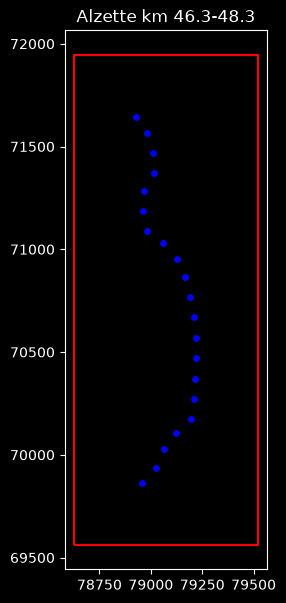

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 7))
aoi.boundary.plot(ax=ax, color="red", linewidth=1.5)
points.plot(ax=ax, color="blue", markersize=15)
ax.set_aspect("equal")
ax.set_title(f"{config['river']} km {config['km_start']}-{config['km_end']}")

## 3. Clip a raw dataset to the AOI

`load_clipped()` in `src/clip.py` reads a vector dataset, reprojects it to the AOI's CRS if needed,
clips it to the AOI polygon, and fixes any invalid geometries. It pre-filters by the AOI's bounding
box *before* reading, which is what keeps this fast even for a country-wide file - e.g. the land cover
geodatabase used elsewhere in this project is 13 GB, and `load_clipped()` never loads it in full.

Here we clip the HQ100 flood hazard layer as an example:

1 row(s) after clipping


<Axes: >

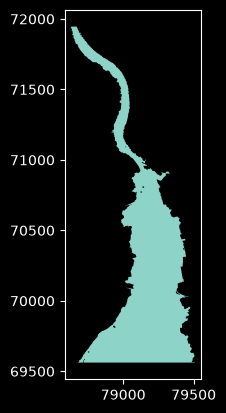

In [9]:
from src.clip import dissolve_footprint, load_clipped

hq100_path = REPO_ROOT / "data/raw/Flood_hazard_HQ100/HWGK2021_HQ100/HWGK2021_HQ100.shp"
hq100 = load_clipped(hq100_path, aoi, crs=config["crs"])
print(f"{len(hq100)} row(s) after clipping")
hq100.plot()

`dissolve_footprint()` merges all rows into a single footprint polygon - useful when a dataset has
multiple overlapping/adjacent polygons and you want one clean shape to compute area from, without
double-counting overlaps:

Flooded area: 623,066 m2 (29.2% of AOI)


<Axes: >

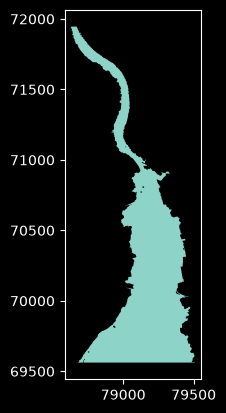

In [10]:
hq100_footprint = dissolve_footprint(hq100)
flooded_area = hq100_footprint.geometry.area.sum()
aoi_area = aoi.geometry.area.sum()
print(f"Flooded area: {flooded_area:,.0f} m2 ({100 * flooded_area / aoi_area:.1f}% of AOI)")
hq100_footprint.plot()

### Caching a clip to disk

Pass `out_path`/`out_layer` and `load_clipped()` will save the result as a layer in a GeoPackage and
skip re-clipping on the next call, as long as the source path, layer, CRS, and AOI (geometry +
attributes) are unchanged - it writes a small `<out_path>.cache.json` sidecar to check this. Set
`overwrite=True` to force a redo. This is exactly what `scripts/landcover_in_flood_zone.py` uses to
avoid re-clipping the 13 GB land cover file on every run.

In [11]:
clipped_path = REPO_ROOT / "data/processed/clipped.gpkg"

hq100_again = load_clipped(
    hq100_path, aoi, crs=config["crs"], out_path=clipped_path, out_layer="hq100_clipped"
)
# Running this cell a second time without changing aoi/config prints "reusing cached layer" instead
# of re-clipping.

[cache] hq100_clipped: (re)computed and cached to /home/manzana/Data_Science/Uni/Semester_3/Workshop_3/urban-digital-twin-alzette-luxembourg/data/processed/clipped.gpkg
